# Model evaluation

**The question:** given two people, do they actually like each other?

This notebook measures any model against that question, using the same users, labels, and metrics every time. It already runs on simple baselines, so a real model only has to be added in one cell.

### How to evaluate your model
1. Train only on `train`, and tune only on `validation`.
2. Add your model to `MODELS` in the "Models" section. It takes a table of public profile fields and returns one like probability per row.
3. Run the whole notebook. Results are added to `exports/evaluation_results.json`, and each new model is logged in `exports/evaluation_log.csv`.

**Treat the test set as one-time.** Every look at it can influence later choices and make the results flatter the model. The log shows how many times each model has been tested.

### What's measured

| Metric | Question it answers |
| --- | --- |
| **Accuracy** | How often is it right? Misleading here, because most pairs don't like each other |
| **Precision** | When it says they like each other, how often is that true? |
| **Recall** | Of the real likes, how many did it find? |
| **F1** | The balance of precision and recall |
| **Type 1 rate** | Of those who don't like each other, how many did it wrongly say do? (false positives) |
| **Type 2 rate** | Of those who do like each other, how many did it miss? (false negatives) |
| **Bias** | Does it overpredict (above 0) or underpredict (below 0) likes? Also checked by group |
| **ROC AUC, PR AUC** | How well does it rank, at any threshold? PR AUC suits rare positives better |
| **Brier, log loss, calibration** | Can its probabilities be trusted? |
| **MCC, balanced accuracy** | Overall quality that isn't fooled by rare positives |
| **Within-rater AUC, precision at 3** | For one person, does it order their candidates well? |
| **Expected matches, exposure** | Does a matcher using it produce more matches, without ignoring most users? |

## Setup

In [1]:
import json
import sys
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from evaluation import (
    LIKE_THRESHOLD,
    best_f1_threshold,
    bootstrap_intervals,
    calibration_table,
    classification_metrics,
    directional_examples,
    expected_calibration_error,
    exposure_gini,
    load_or_create_splits,
    load_ratings,
    mutual_examples,
    public_profiles,
    ranking_metrics,
    subgroup_table,
)
from run_metrics import compute_metrics
from paths import MAIN_DB
from store import RunNotFoundError, Store

BASELINE_RUN = "random-baseline-100k"
TEST_PAIRS_RUN = "eval-test-pairs"  # Made by scripts/build_test_pairs.py. Used if it exists.
SPLITS_PATH = ROOT / "exports" / "user_splits.json"
RESULTS_PATH = ROOT / "exports" / "evaluation_results.json"
LOG_PATH = ROOT / "exports" / "evaluation_log.csv"
FIGURE_DIR = ROOT / "notebooks" / "figures"
BASELINE_MODELS = {"Always no", "Base rate", "Profile logistic"}
SEED = 42
JEV_NOISE_SD = 0.014  # From repeated ratings in notebooks/final_dataset_check.ipynb.
MIN_POSITIVES = 100

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED,
    "axes.titlecolor": INK,
    "axes.titlesize": 11,
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.bottom": False,
    "ytick.left": False,
    "text.color": INK,
    "font.size": 10,
    "figure.dpi": 120,
})


def save_figure(fig, name):
    FIGURE_DIR.mkdir(exist_ok=True)
    fig.savefig(FIGURE_DIR / f"evaluation_{name}.png", dpi=160, bbox_inches="tight")

## Data

Users are split once and saved to `exports/user_splits.json`, so the test users never change. A rating is only used if **both** people are in the same split, so no test user's ratings can reach training.

Two tasks are measured, because a matcher needs both:
- **Directional:** does this person like that profile?
- **Mutual:** do both people like each other? This is your main question, and a pair must have rated each other to count.

In [2]:
store = Store(MAIN_DB)
try:
    store.get_run(TEST_PAIRS_RUN)
    test_runs = [BASELINE_RUN, TEST_PAIRS_RUN]
except RunNotFoundError:
    test_runs = [BASELINE_RUN]

profiles = public_profiles(store)
splits = load_or_create_splits(SPLITS_PATH, profiles)
baseline_ratings = load_ratings(store, [BASELINE_RUN])

train = directional_examples(baseline_ratings, splits, "train", profiles)
validation = directional_examples(baseline_ratings, splits, "validation", profiles)
test = directional_examples(load_ratings(store, test_runs), splits, "test", profiles)

data_summary = []
for name, frame in (("train", train), ("validation", validation), ("test", test)):
    pairs = mutual_examples(frame)
    data_summary.append({
        "split": name,
        "users": sum(value == name for value in splits.values()),
        "ratings": len(frame),
        "like_rate": frame["like"].mean(),
        "pairs_rated_both_ways": len(pairs),
        "mutual_likes": int(pairs["mutual"].sum()),
        "mutual_rate": pairs["mutual"].mean() if len(pairs) else np.nan,
    })
data_summary = pd.DataFrame(data_summary).set_index("split")
test_mutual_likes = int(data_summary.loc["test", "mutual_likes"])
if test_mutual_likes < MIN_POSITIVES:
    print(
        f"WARNING: the test set has only {test_mutual_likes} mutual likes, so mutual results are very uncertain.\n"
        "Run scripts/build_test_pairs.py before judging a model on them."
    )
data_summary.round(3)

Run scripts/build_test_pairs.py before judging a model on them.


,users,ratings,like_rate,pairs_rated_both_ways,mutual_likes,mutual_rate
split,,,,,,
train,1280,41276,0.264,1222,150,0.123
validation,320,2496,0.274,74,9,0.122
test,400,3965,0.281,143,23,0.161


### Is 0.5 the right cut-off for a "like"?

Jev gives a probability, so "like" means a score of at least `LIKE_THRESHOLD`, which is 0.5. Any cut-off is a choice, and it changes how rare a like is. Keep it fixed when comparing models.

In [3]:
all_pairs = mutual_examples(load_ratings(store, [BASELINE_RUN]))
pd.DataFrame([
    {
        "like_cutoff": cutoff,
        "like_rate": (baseline_ratings["score"] >= cutoff).mean(),
        "mutual_rate": ((all_pairs["score"] >= cutoff) & (all_pairs["score_reverse"] >= cutoff)).mean(),
    }
    for cutoff in (0.3, 0.4, 0.5, 0.6, 0.7)
]).set_index("like_cutoff").round(3)

,like_rate,mutual_rate
like_cutoff,,
0.3,0.453,0.322
0.4,0.358,0.224
0.5,0.271,0.134
0.6,0.178,0.067
0.7,0.089,0.020


## Models

Each model takes a table with one row per (rater, target) and returns one probability that the rater likes the target. A pair's match probability is the product of its two directions.

The three baselines show what's easy:
- **Always no:** shows how good accuracy can look while finding nothing.
- **Base rate:** gives everyone the average like rate from training.
- **Profile logistic:** a simple logistic regression on public profile fields. **Your model should clearly beat this one.**

Columns available to a model are `rater_id`, `target_id`, and `rater_*` and `target_*` profile fields. **Don't use `score` or `like` from the table you're predicting, since those are the answers.** Personas aren't in these tables, and neither is the agent flag.

In [4]:
ANSWER_COLUMNS = ["score", "like"]


def profile_features(examples):
    """Simple public features, some of which compare the two people."""
    features = pd.DataFrame(index=examples.index)
    features["same_goal"] = (examples["rater_looking_for"] == examples["target_looking_for"]).astype(float)
    features["same_religion"] = (examples["rater_religion"] == examples["target_religion"]).astype(float)
    features["same_major"] = (examples["rater_major"] == examples["target_major"]).astype(float)
    features["age_gap"] = (examples["rater_age"] - examples["target_age"]).abs()
    features["height_gap"] = (examples["rater_height_cm"] - examples["target_height_cm"]).abs()
    features["shared_interests_and_clubs"] = [
        len(set(a + b) & set(c + d))
        for a, b, c, d in zip(examples["rater_interests"], examples["rater_clubs"], examples["target_interests"], examples["target_clubs"])
    ]
    goal_pairs = examples["rater_looking_for"] + " wants, target " + examples["target_looking_for"]
    categories = pd.concat([
        pd.get_dummies(goal_pairs, prefix="goals"),
        pd.get_dummies(examples["rater_religion"], prefix="rater_religion"),
        pd.get_dummies(examples["rater_gender"], prefix="rater_gender"),
    ], axis=1).astype(float)
    return pd.concat([features, categories], axis=1)


feature_columns = profile_features(train).columns
logistic = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
logistic.fit(profile_features(train), train["like"])
base_rate = train["like"].mean()

MODELS = {
    "Always no": lambda examples: np.zeros(len(examples)),
    "Base rate": lambda examples: np.full(len(examples), base_rate),
    "Profile logistic": lambda examples: logistic.predict_proba(
        profile_features(examples).reindex(columns=feature_columns, fill_value=0.0)
    )[:, 1],
    # ADD YOUR MODEL HERE, for example:
    # "My model": lambda examples: my_model.predict_like_probability(examples),
}

print(f"Training like rate: {base_rate:.3f}. Profile logistic mean probability on training data: {MODELS['Profile logistic'](train).mean():.3f}")

Training like rate: 0.264. Profile logistic mean probability on training data: 0.264


## Evaluate

Decision thresholds are chosen on validation only, to give the best F1, then applied unchanged to the test set. **Always no** keeps a fixed threshold, since it has nothing to tune.

In [5]:
def predictions(model, examples):
    probability = np.asarray(model(examples.drop(columns=ANSWER_COLUMNS)), dtype=float)
    if len(probability) != len(examples) or not np.all((probability >= 0) & (probability <= 1)):
        raise ValueError("a model must return one probability from 0 to 1 per row")
    return probability


directional_rows, mutual_rows = {}, {}
thresholds = {}
test_probability = {}
test_pairs = {}
for name, model in MODELS.items():
    validation_probability = predictions(model, validation)
    validation_pairs = mutual_examples(validation, validation_probability)
    if name == "Always no":
        directional_threshold = mutual_threshold = 0.5
    else:
        directional_threshold = best_f1_threshold(validation["like"], validation_probability)
        mutual_threshold = best_f1_threshold(validation_pairs["mutual"], validation_pairs["match_probability"])
    thresholds[name] = {"directional": directional_threshold, "mutual": mutual_threshold}

    test_probability[name] = predictions(model, test)
    test_pairs[name] = mutual_examples(test, test_probability[name])
    directional_rows[name] = classification_metrics(test["like"].to_numpy(), test_probability[name], directional_threshold)
    mutual_rows[name] = classification_metrics(test_pairs[name]["mutual"].to_numpy(), test_pairs[name]["match_probability"].to_numpy(), mutual_threshold)
    directional_rows[name]["threshold"] = directional_threshold
    mutual_rows[name]["threshold"] = mutual_threshold

SHOW = ["n", "positive_rate", "threshold", "accuracy", "balanced_accuracy", "precision", "recall", "f1", "type_1_rate", "type_2_rate", "bias", "mcc", "roc_auc", "pr_auc", "brier", "log_loss"]
directional_table = pd.DataFrame(directional_rows).loc[SHOW]
mutual_table = pd.DataFrame(mutual_rows).loc[SHOW]
print("Validation pairs used to choose the mutual threshold:", len(mutual_examples(validation)))

Validation pairs used to choose the mutual threshold: 74


### Directional: does this person like that profile?

In [6]:
directional_table.round(3)

,Always no,Base rate,Profile logistic
n,3965.000,3965.000,3965.000
positive_rate,0.281,0.281,0.281
threshold,0.500,0.264,0.353
accuracy,0.719,0.281,0.729
balanced_accuracy,0.500,0.500,0.742
precision,NaN,0.281,0.512
recall,0.000,1.000,0.769
f1,0.000,0.439,0.615
type_1_rate,0.000,1.000,0.286
type_2_rate,1.000,0.000,0.231


### Mutual: do both people like each other?

In [7]:
mutual_table.round(3)

,Always no,Base rate,Profile logistic
n,143.000,143.000,143.000
positive_rate,0.161,0.161,0.161
threshold,0.500,0.070,0.259
accuracy,0.839,0.161,0.881
balanced_accuracy,0.500,0.500,0.789
precision,NaN,0.161,0.625
recall,0.000,1.000,0.652
f1,0.000,0.277,0.638
type_1_rate,0.000,1.000,0.075
type_2_rate,1.000,0.000,0.348


### Best possible score

Jev's answers vary slightly when repeated, so no model can be perfect. This treats Jev's own score, with its repeat noise added, as a prediction. It's a rough ceiling, since it knows the score almost exactly.

In [8]:
noise = np.random.default_rng(SEED)
ceiling_direct = np.clip(test["score"] + noise.normal(0, JEV_NOISE_SD, len(test)), 0, 1)
pairs = test_pairs["Base rate"]
noisy_a = pairs["score"] + noise.normal(0, JEV_NOISE_SD, len(pairs))
noisy_b = pairs["score_reverse"] + noise.normal(0, JEV_NOISE_SD, len(pairs))
ceiling_mutual = ((noisy_a >= LIKE_THRESHOLD) & (noisy_b >= LIKE_THRESHOLD)).astype(float)
ceiling = pd.DataFrame({
    "Directional": classification_metrics(test["like"].to_numpy(), ceiling_direct.to_numpy(), LIKE_THRESHOLD),
    "Mutual": classification_metrics(pairs["mutual"].to_numpy(), ceiling_mutual.to_numpy(), 0.5),
}).loc[["accuracy", "precision", "recall", "f1", "type_1_rate", "type_2_rate"]]
ceiling.round(3)

,Directional,Mutual
accuracy,0.993,0.993
precision,0.990,1.000
recall,0.984,0.957
f1,0.987,0.978
type_1_rate,0.004,0.000
type_2_rate,0.016,0.043


### Confidence intervals

These resample **users**, because ratings from one person aren't independent. The differences compare each model with **Base rate** on the same resamples. If a difference interval excludes 0, the gap is unlikely to be chance. Change `FOCUS_MODEL` to your model.

In [9]:
FOCUS_MODEL = "Profile logistic"
INTERVAL_METRICS = ["accuracy", "precision", "recall", "f1", "type_1_rate", "type_2_rate", "bias", "roc_auc", "pr_auc", "brier"]

directional_intervals = bootstrap_intervals(
    test["like"].to_numpy(), test_probability[FOCUS_MODEL], thresholds[FOCUS_MODEL]["directional"],
    test["rater_id"].to_numpy(), baseline_probability=test_probability["Base rate"],
    baseline_threshold=thresholds["Base rate"]["directional"], n_samples=200,
).loc[INTERVAL_METRICS]
directional_intervals.insert(0, "estimate", directional_table[FOCUS_MODEL].loc[INTERVAL_METRICS])

focus_pairs = test_pairs[FOCUS_MODEL]
mutual_intervals = bootstrap_intervals(
    focus_pairs["mutual"].to_numpy(), focus_pairs["match_probability"].to_numpy(), thresholds[FOCUS_MODEL]["mutual"],
    focus_pairs["user_a"].to_numpy(), focus_pairs["user_b"].to_numpy(),
    baseline_probability=test_pairs["Base rate"]["match_probability"].to_numpy(),
    baseline_threshold=thresholds["Base rate"]["mutual"], n_samples=200,
).loc[INTERVAL_METRICS]
mutual_intervals.insert(0, "estimate", mutual_table[FOCUS_MODEL].loc[INTERVAL_METRICS])
print("Directional:")
print(directional_intervals.round(3).to_string())
print()
print("Mutual:")
print(mutual_intervals.round(3).to_string())

Directional:
             estimate    low   high  difference_low  difference_high
accuracy        0.729  0.704  0.751           0.406            0.484
precision       0.512  0.476  0.557           0.203            0.259
recall          0.769  0.726  0.811          -0.274           -0.189
f1              0.615  0.585  0.651           0.137            0.204
type_1_rate     0.286  0.260  0.316          -0.740           -0.684
type_2_rate     0.231  0.189  0.274           0.189            0.274
bias           -0.006 -0.031  0.016          -0.004            0.024
roc_auc         0.831  0.811  0.853           0.311            0.353
pr_auc          0.606  0.562  0.655           0.283            0.368
brier           0.146  0.136  0.157          -0.066           -0.048

Mutual:
             estimate    low   high  difference_low  difference_high
accuracy        0.881  0.786  0.961           0.541            0.857
precision       0.625  0.281  0.929           0.151            0.758
recall      

## Charts

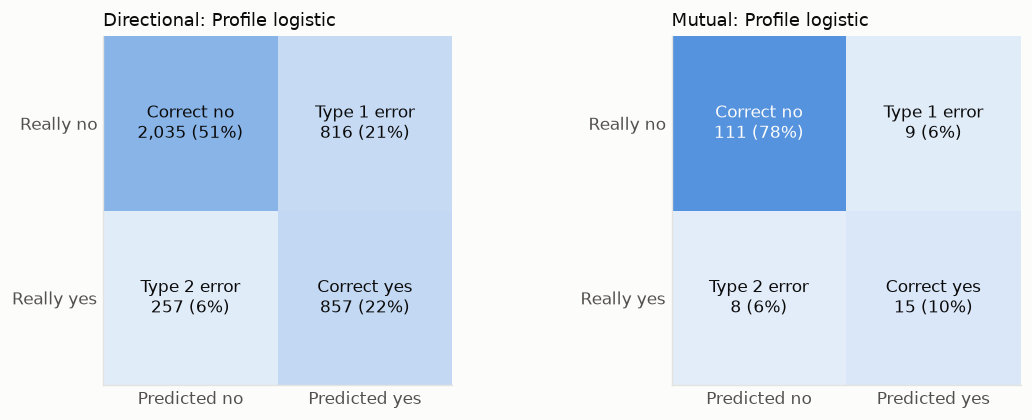

In [10]:
def error_chart(ax, tn, fp, fn, tp, title):
    grid = np.array([[tn, fp], [fn, tp]])
    ax.imshow(grid / grid.sum(), cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("share", ["#eef4fc", BLUE]), vmin=0, vmax=1)
    labels = [["Correct no", "Type 1 error"], ["Type 2 error", "Correct yes"]]
    for row in range(2):
        for column in range(2):
            share = grid[row, column] / grid.sum()
            ax.text(column, row, f"{labels[row][column]}\n{int(grid[row, column]):,} ({share:.0%})", ha="center", va="center", color=SURFACE if share > 0.55 else INK)
    ax.set_xticks([0, 1], ["Predicted no", "Predicted yes"])
    ax.set_yticks([0, 1], ["Really no", "Really yes"])
    ax.set_title(title)
    ax.grid(False)
    ax.tick_params(length=0)


fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, table, title in ((axes[0], directional_table, "Directional"), (axes[1], mutual_table, "Mutual")):
    d = pd.DataFrame(directional_rows if title == "Directional" else mutual_rows)[FOCUS_MODEL]
    error_chart(ax, d["tn"], d["fp"], d["fn"], d["tp"], f"{title}: {FOCUS_MODEL}")
fig.tight_layout()
save_figure(fig, "type_1_and_type_2_errors")
plt.show()

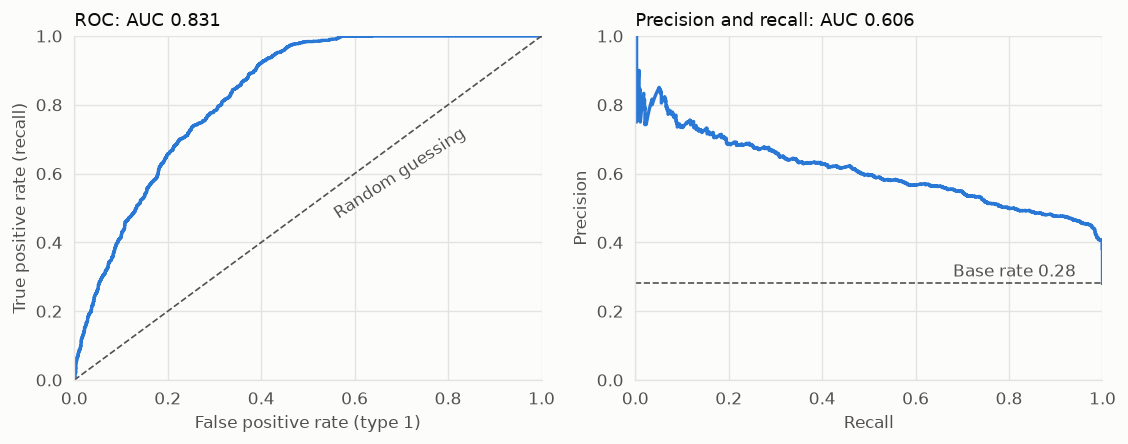

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
y, p = test["like"].to_numpy(), test_probability[FOCUS_MODEL]
fpr, tpr, _ = roc_curve(y, p)
axes[0].plot(fpr, tpr, color=BLUE, linewidth=2)
axes[0].plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle="--")
axes[0].annotate("Random guessing", (0.55, 0.47), color=MUTED, rotation=33)
axes[0].set_title(f"ROC: AUC {directional_rows[FOCUS_MODEL]['roc_auc']:.3f}")
axes[0].set_xlabel("False positive rate (type 1)")
axes[0].set_ylabel("True positive rate (recall)")
precision, recall, _ = precision_recall_curve(y, p)
axes[1].plot(recall, precision, color=BLUE, linewidth=2)
axes[1].axhline(y.mean(), color=MUTED, linewidth=1, linestyle="--")
axes[1].annotate(f"Base rate {y.mean():.2f}", (0.68, y.mean() + 0.02), color=MUTED)
axes[1].set_title(f"Precision and recall: AUC {directional_rows[FOCUS_MODEL]['pr_auc']:.3f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
fig.tight_layout()
save_figure(fig, "roc_and_precision_recall")
plt.show()

### Calibration

Points on the diagonal mean the probabilities can be trusted: among pairs given 0.6, about 60% really do like. A matcher relies on this, because a match probability is the product of two predicted probabilities.

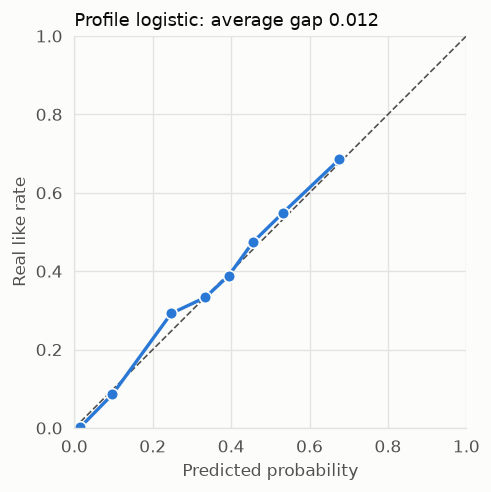

In [12]:
fig, ax = plt.subplots(figsize=(4.6, 4.2))
table = calibration_table(test["like"], test_probability[FOCUS_MODEL])
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle="--")
ax.plot(table["predicted"], table["observed"], color=BLUE, linewidth=2, marker="o", markersize=7, markeredgecolor=SURFACE)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal")
ax.set_xlabel("Predicted probability")
ax.set_ylabel("Real like rate")
ece = expected_calibration_error(test["like"], test_probability[FOCUS_MODEL])
ax.set_title(f"{FOCUS_MODEL}: average gap {ece:.3f}")
fig.tight_layout()
save_figure(fig, "calibration")
plt.show()

## Bias across groups

Overall numbers can hide a model that works well for some people and badly for others. Here, **type 1 and type 2 rates and bias** are compared by group. Large gaps suggest a fairness problem. Groups marked `small_sample` have under 30 ratings, so ignore their exact numbers.

In [13]:
interest = store.all_preferences()  # Private, and used here only to group the results.
groups = {
    "Rater gender": test["rater_gender"],
    "Rater relationship goal": test["rater_looking_for"],
    "Rater religion": test["rater_religion"],
    "Rater age": pd.cut(test["rater_age"], [17, 20, 22, 24], labels=["18 to 20", "21 to 22", "23 to 24"]).astype(str),
    "Same-gender interest": pd.Series(np.where([g in interest[r] for g, r in zip(test["rater_gender"], test["rater_id"])], "yes", "no"), index=test.index),
    "Target gender": test["target_gender"],
    "Target religion": test["target_religion"],
}
threshold = thresholds[FOCUS_MODEL]["directional"]
subgroups = pd.concat({
    name: subgroup_table(values, test["like"].to_numpy(), test_probability[FOCUS_MODEL], threshold)
    for name, values in groups.items()
}, names=["grouping", "group"])
subgroups.round(3)

n  positive_rate  accuracy     f1  \
grouping                group                                               
Rater gender            man          2063          0.309     0.733  0.680   
                        woman        1902          0.250     0.725  0.510   
Rater relationship goal just a date  1369          0.356     0.653  0.616   
                        long-term    1108          0.110     0.890  0.611   
                        short-term   1488          0.339     0.680  0.615   
Rater religion          agnostic      389          0.326     0.694  0.667   
                        atheist       421          0.247     0.743  0.625   
                        buddhist      416          0.308     0.690  0.615   
                        catholic      389          0.332     0.728  0.624   
                        christian     450          0.247     0.762  0.590   
                        hindu         355          0.301     0.715  0.658   
                        jewish        379          0.187     0.720  0.470   
                        mormon        470          0.272     0.687  0.458   
                        muslim        335          0.167     0.806  0.511   
                        spiritual     361          0.424     0.765  0.767   
Rater age               18 to 20     1937          0.309     0.748  0.653   
                        21 to 22     1033          0.286     0.702  0.606   
                        23 to 24      995          0.221     0.723  0.535   
Same-gender interest    no           3881          0.281     0.727  0.611   
                        yes            84          0.298     0.857  0.793   
Target gender           man          1962          0.251     0.728  0.520   
                        woman        2003          0.310     0.730  0.678   
Target religion         agnostic      382          0.309     0.746  0.660   
                        atheist       430          0.179     0.723  0.506   
                        buddhist      426          0.296     0.707  0.618   
                        catholic      362          0.293     0.809  0.723   
                        christian     406          0.293     0.729  0.596   
                        hindu         392          0.224     0.709  0.525   
                        jewish        407          0.265     0.703  0.566   
                        mormon        472          0.292     0.710  0.625   
                        muslim        302          0.315     0.715  0.629   
                        spiritual     386          0.360     0.754  0.680   

                                     type_1_rate  type_2_rate   bias  \
grouping                group                                          
Rater gender            man                0.349        0.083  0.002   
                        woman              0.224        0.429 -0.014   
Rater relationship goal just a date        0.418        0.219  0.009   
                        long-term          0.097        0.213  0.006   
                        short-term         0.358        0.246 -0.028   
Rater religion          agnostic           0.424        0.063  0.017   
                        atheist            0.297        0.135  0.021   
                        buddhist           0.361        0.195 -0.007   
                        catholic           0.250        0.318 -0.073   
                        christian          0.215        0.306 -0.022   
                        hindu              0.367        0.093  0.009   
                        jewish             0.266        0.338  0.055   
                        mormon             0.237        0.516 -0.025   
                        muslim             0.154        0.393  0.038   
                        spiritual          0.346        0.085 -0.061   
Rater age               18 to 20           0.262        0.230 -0.028   
                        21 to 22           0.339        0.197  0.002   
                        23 to 24           0.277     

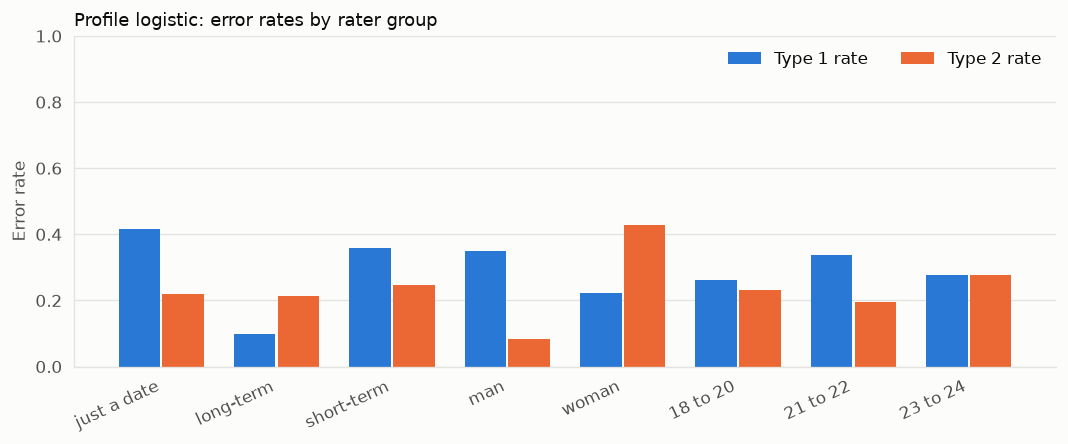

In [14]:
plot_group = subgroups.loc["Rater relationship goal"]
for extra in ("Rater gender", "Rater age"):
    plot_group = pd.concat([plot_group, subgroups.loc[extra]])
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(plot_group))
width = 0.36
for offset, column, color, label in ((-width / 2 - 0.01, "type_1_rate", BLUE, "Type 1 rate"), (width / 2 + 0.01, "type_2_rate", ORANGE, "Type 2 rate")):
    ax.bar(x + offset, plot_group[column], width, color=color, label=label)
ax.set_xticks(x, plot_group.index, rotation=25, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("Error rate")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, ncols=2, loc="upper right")
ax.set_title(f"{FOCUS_MODEL}: error rates by rater group")
fig.tight_layout()
save_figure(fig, "errors_by_group")
plt.show()

## Ranking for one person

A matcher chooses among a person's candidates, so this compares candidates **for the same rater**. A model can reach a good overall AUC just by learning that some people like everyone, so this is often lower. `lift_at_3` is how much the top 3 beat that person's average.

In [15]:
ranking = pd.DataFrame({name: ranking_metrics(test["rater_id"], test["like"].to_numpy(), test_probability[name]) for name in MODELS})
ranking.round(3)

,Always no,Base rate,Profile logistic
within_rater_auc,0.500,0.500,0.836
precision_at_3,0.369,0.369,0.601
lift_at_3,0.005,0.005,0.237
raters_counted,301.000,301.000,301.000


## Run-level metrics

Pair metrics can't show whether a matcher creates matches when it actually runs. Run a new matcher with `scripts/run_experiment.py`, and add its run ID here. **Expected matches per 1,000 ratings** is the main number. **Exposure Gini** shows whether attention goes to a few users: 0 means everyone is shown equally, and higher means a few get most of it.

In [16]:
RUNS_TO_COMPARE = [BASELINE_RUN]  # Add your matcher's run ID here.
run_rows = {}
for run_id in RUNS_TO_COMPARE:
    result = compute_metrics(store, run_id)
    received = load_ratings(store, [run_id])["target_id"].value_counts()
    received = received.reindex(profiles.keys(), fill_value=0)
    run_rows[run_id] = {
        "ratings": result.n_ratings,
        "mean_like": result.mean_score,
        "pairs_rated_both_ways": result.pairs_rated_both_ways,
        "expected_matches": result.expected_matches,
        "expected_matches_per_1000_ratings": result.expected_matches / result.n_ratings * 1000,
        "match_chance_per_pair": result.match_rate,
        "exposure_gini": exposure_gini(received),
    }
run_table = pd.DataFrame(run_rows)
run_table.round(3)

,random-baseline-100k
ratings,99999.000
mean_like,0.324
pairs_rated_both_ways,3104.000
expected_matches,413.979
expected_matches_per_1000_ratings,4.140
match_chance_per_pair,0.133
exposure_gini,0.087


## Save the results

In [17]:
def to_json(frame):
    return json.loads(frame.to_json())


results = {
    "created": datetime.now().isoformat(timespec="seconds"),
    "like_threshold": LIKE_THRESHOLD,
    "test_runs": test_runs,
    "data": to_json(data_summary),
    "directional": to_json(directional_table),
    "mutual": to_json(mutual_table),
    "ceiling": to_json(ceiling),
    "ranking": to_json(ranking),
    "run_level": to_json(run_table),
}
RESULTS_PATH.write_text(json.dumps(results, indent=2))

new_models = [name for name in MODELS if name not in BASELINE_MODELS]
if new_models:
    log = pd.DataFrame([
        {
            "time": results["created"],
            "model": name,
            "directional_f1": directional_rows[name]["f1"],
            "mutual_f1": mutual_rows[name]["f1"],
            "directional_pr_auc": directional_rows[name]["pr_auc"],
            "mutual_pr_auc": mutual_rows[name]["pr_auc"],
        }
        for name in new_models
    ])
    log.to_csv(LOG_PATH, mode="a", index=False, header=not LOG_PATH.exists())
print("Saved to", RESULTS_PATH.relative_to(ROOT))
print("Test-set runs logged for:", new_models or "no new models")

Saved to exports/evaluation_results.json
Test-set runs logged for: no new models


## Reading these baseline results

**The evaluation works from end to end and is ready for a real model. `Profile logistic` is the score to beat.** The numbers below are from the test users. The mutual results rest on only 143 pairs and 23 mutual likes, so their intervals are very wide.

| Metric | Task | Always no | Base rate | Profile logistic | Rough ceiling |
| --- | --- | --- | --- | --- | --- |
| Accuracy | Directional | 0.719 | 0.281 | 0.729 | 0.993 |
| F1 | Directional | 0.000 | 0.439 | **0.615** | 0.987 |
| Type 1 rate | Directional | 0.000 | 1.000 | 0.286 | 0.004 |
| Type 2 rate | Directional | 1.000 | 0.000 | 0.231 | 0.016 |
| F1 | Mutual | 0.000 | 0.277 | **0.638** | 0.978 |
| Accuracy | Mutual | 0.839 | 0.161 | 0.881 | 0.993 |

- **Accuracy misleads here:** answering "no" every time scores 0.84 on mutual likes while finding none of them. Compare models on F1, PR AUC, and both error rates.
- **The bar is already fairly high:** public profile fields alone reach a directional ROC AUC of 0.83 and a within-rater AUC of 0.84. Personas were written from profiles, so public data predicts a lot of what they say. A real model needs to clearly beat this, not just the random baseline.
- **Overall bias is small, but errors vary by group:** F1 is 0.68 for men rating and 0.51 for women rating, partly because the like rate differs. Compare these again for any real model.

**Limits:**
- **Too few mutual test pairs:** run `scripts/build_test_pairs.py` before relying on mutual results. This changes the numbers above.
- **Thresholds rest on a small sample:** the mutual threshold was chosen on only 74 validation pairs, so it's unstable.
- **Truth is Jev's estimate:** this measures agreement with Jev about invented people, and the 0.5 cut-off is a choice. It doesn't measure real human behavior.
- **The ceiling is only rough:** it assumes the only error is Jev's repeat noise, which came from a small sample.
